Number of each pitch type
pitch_type
CH    127
CU    136
FC    196
FF    937
FS    402
KC    174
SI    145
SL    540
ST    131
Name: pitch_type, dtype: int64






Probability of each pitch type
pitch_type
CH    0.046
CU    0.049
FC    0.070
FF    0.336
FS    0.144
KC    0.062
SI    0.052
SL    0.194
ST    0.047
Name: pitch_type, dtype: float64






Combined count & probability table
            count  probability
pitch_type                    
CH            127        0.046
CU            136        0.049
FC            196        0.070
FF            937        0.336
FS            402        0.144
KC            174        0.062
SI            145        0.052
SL            540        0.194
ST            131        0.047






Naive Baseline Accuracy: 33.6 %


,count,probability
pitch_type,,
CH,127,0.046
CU,136,0.049
FC,196,0.070
FF,937,0.336
FS,402,0.144
KC,174,0.062
SI,145,0.052
SL,540,0.194
ST,131,0.047


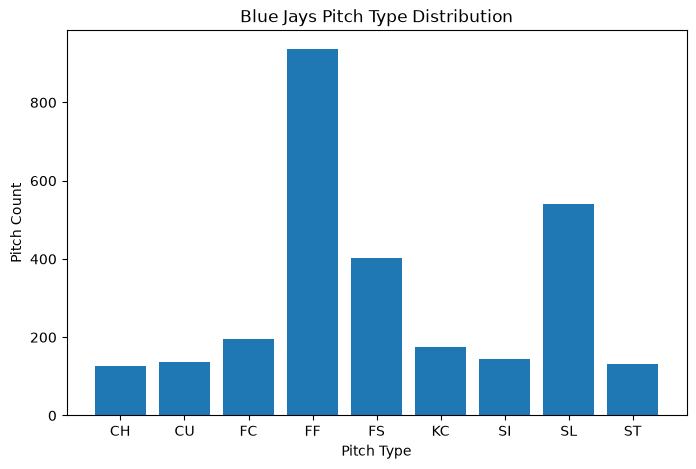

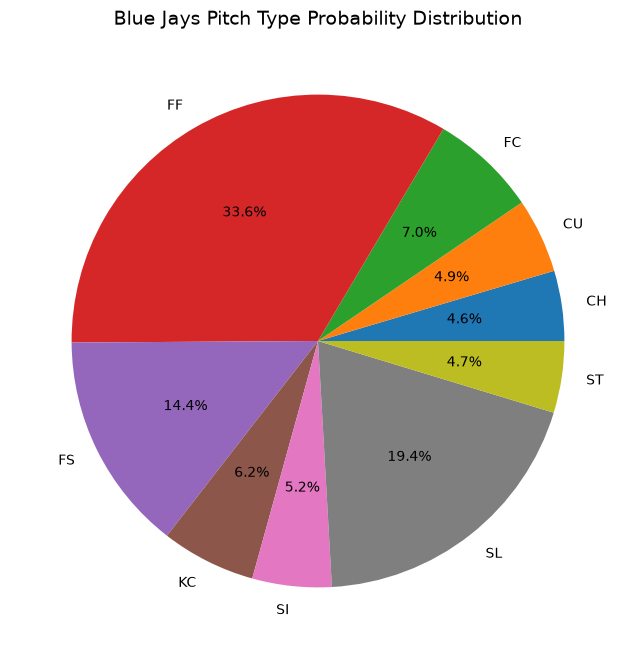

In [1]:
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML

# Read the pitch‑by‑postseason dataset, keep your original file path
df = pd.read_csv("Data_MLB_2025_StatcastPostseason_PitchByPitch_20251102a.csv")

# Subquestion 1: How predictable is pitch selection overall?
# Filter rows: only pitches thrown by Toronto Blue Jays pitchers
# When TOR is home team: Blue Jays pitch in Top of inning
# When TOR is away team: Blue Jays pitch in Bottom of inning
pitch_toronto = (
    ((df["home_team"]=="TOR") & (df["inning_topbot"]=="Top")) |
    ((df["away_team"]=="TOR") & (df["inning_topbot"]=="Bot"))
)

# Create copy dataframe containing only Blue Jays pitching data
toronto = df[pitch_toronto].copy()
toronto["pitch_type"]

# HTML page title and sub‑question heading
html_title = """
<h1>MLB Postseason Blue Jays Pitch Analysis:  How predictable is the next pitch thrown by Toronto Blue Jays pitchers during the 2025 postseason, and which pitch-context and game-state variables are most important for predicting pitch selection</h1>
<h2>Subquestion 1: How predictable is pitch selection overall?</h2>
<h3 style="font-size:16px; font-weight:normal;">1. Useful data</h3>
"""
display(HTML(html_title))

# Count total occurrences for each pitch type
counts_toronto_pitch = toronto.groupby("pitch_type")["pitch_type"].count()
print("Number of each pitch type")
print(counts_toronto_pitch)
print("\n\n\n\n\n")

# Calculate proportion (empirical probability) for each pitch type
pro_toronto_pitch = round( (toronto.groupby("pitch_type")["pitch_type"].count()) / len(toronto["pitch_type"]), 3)
print("Probability of each pitch type")
print(pro_toronto_pitch)
print("\n\n\n\n\n")

# Combine count and probability into one summary table
numpro_table = pd.concat([counts_toronto_pitch, pro_toronto_pitch], axis = 1)
numpro_table.columns = ["count", "probability"]
print("Combined count & probability table")
print(numpro_table)
print("\n\n\n\n\n")

# Compute naive baseline accuracy: always guess the most frequent pitch type
accuracy = pro_toronto_pitch.max()
print(f"Naive Baseline Accuracy: {round(accuracy*100, 1)} %")

# HTML formatted summary table with styling
html_table_part = """
<h4 style="font-size:16px; font-weight:normal;">2. The following table integrates two calculated datasets: <b>counts_toronto_pitch</b> (total number of each pitch type) and <b>pro_toronto_pitch</b> (proportion probability of each pitch type).</h4>
<style>
table {
  border-collapse: collapse;
  width: 65%;
}
th, td {
  border: 1px solid black;
  padding: 8px;
  text-align: center;
  font-size:15px;
}
</style>
"""
html_table_part += numpro_table.to_html(border=0)
display(HTML(html_table_part))

# Description text for bar chart
bar_text = """
<h5 style="font-size:16px; font-weight:normal;">3. The bar chart below visualizes <b>counts_toronto_pitch</b>, showing the raw count of each pitch type thrown by Blue Jays pitchers.</h5>
"""
display(HTML(bar_text))

# Plot bar chart for pitch type raw counts
fig, ax = plt.subplots(figsize=(8,5))
ax.bar(numpro_table.index, numpro_table["count"])
ax.set_xlabel("Pitch Type")
ax.set_ylabel("Pitch Count")
ax.set_title("Blue Jays Pitch Type Distribution")
plt.show()

# Description text for pie chart
pie_text = """
<h6 style="font-size:16px; font-weight:normal;">4. The pie chart below visualizes <b>pro_toronto_pitch</b>, representing the probability distribution for each pitch type.</h6>
"""
display(HTML(pie_text))

# Plot pie chart for pitch type probability distribution
plt.figure(figsize=(8,8))
numpro_table["probability"].plot(kind="pie", autopct="%1.1f%%")
plt.title("Blue Jays Pitch Type Probability Distribution", fontsize=14)
plt.ylabel("")
plt.show()

# Sub‑question 1 final conclusion displayed in HTML
conclusion = f"""
<h3 style="font-size:18px; color:#222; margin-top:25px;">
Subquestion 1 Conclusion: <br/>
Based on the pie chart distribution and calculated baseline accuracy, the Toronto Blue Jays show 
obvious pitch selection patterns. The most frequent pitch type achieves a baseline prediction accuracy of 
<strong>{round(accuracy*100,1)}%</strong>. This means simply guessing the most common pitch can correctly predict pitch selections 
at this rate. The pie chart further proves that pitch types are not evenly distributed, 
which provides a valid baseline for subsequent exploratory data analysis.
</h3>
"""
display(HTML(conclusion))


,count,pitch_type
0,0-0,FF
1,0-1,FF
2,1-1,ST
3,2-1,FF
4,2-2,FF
...,...,...
2783,0-0,FS
2784,0-1,SL
2785,1-1,FS
2786,0-0,SL


,count,pitch_type,pitch_number
0,0-0,CH,26
1,0-0,CU,33
2,0-0,FC,46
3,0-0,FF,307
4,0-0,FS,63
...,...,...,...
97,3-2,FS,17
98,3-2,KC,10
99,3-2,SI,10
100,3-2,SL,23


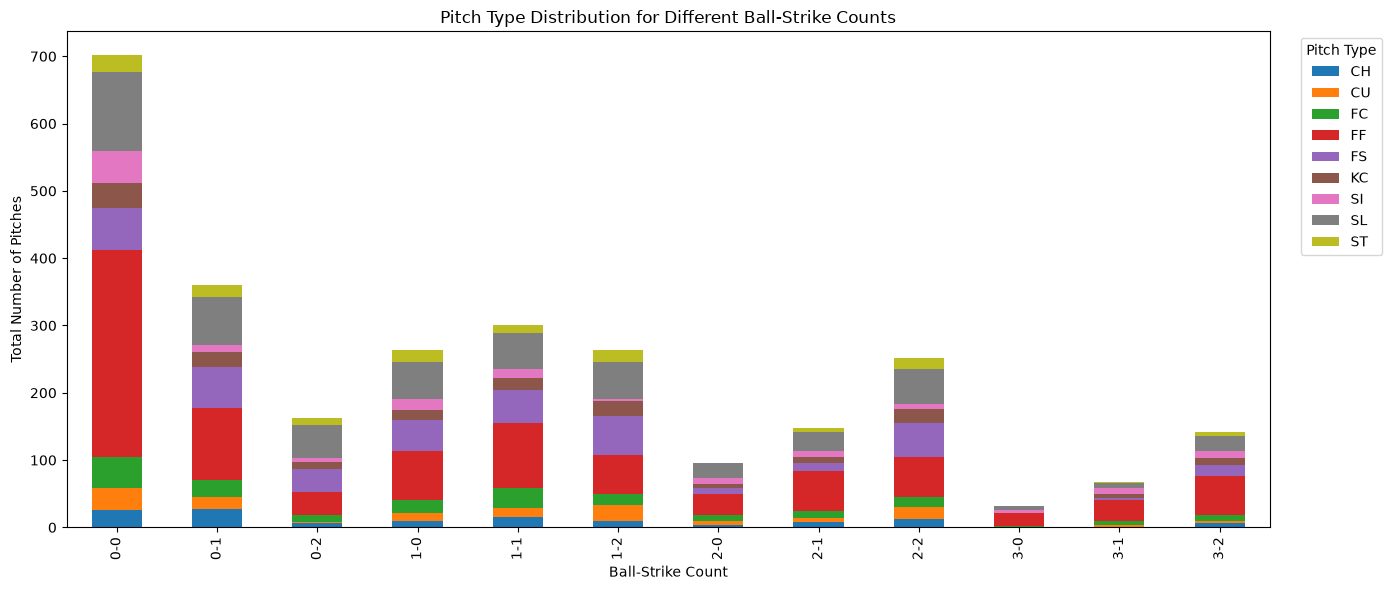

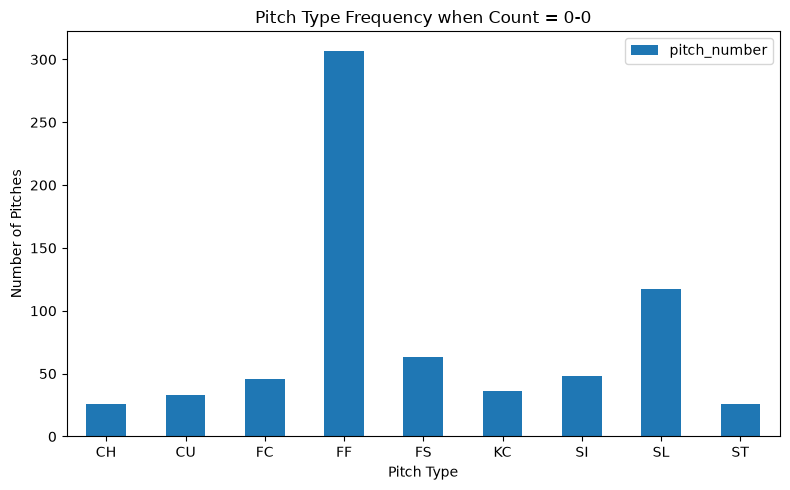

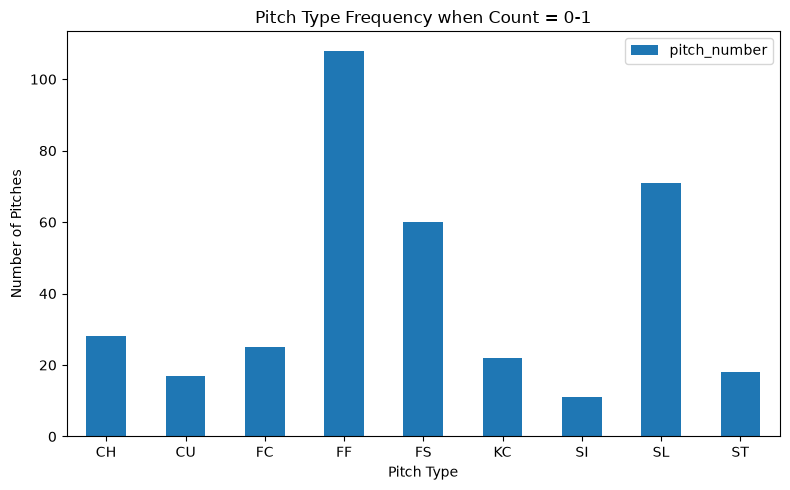

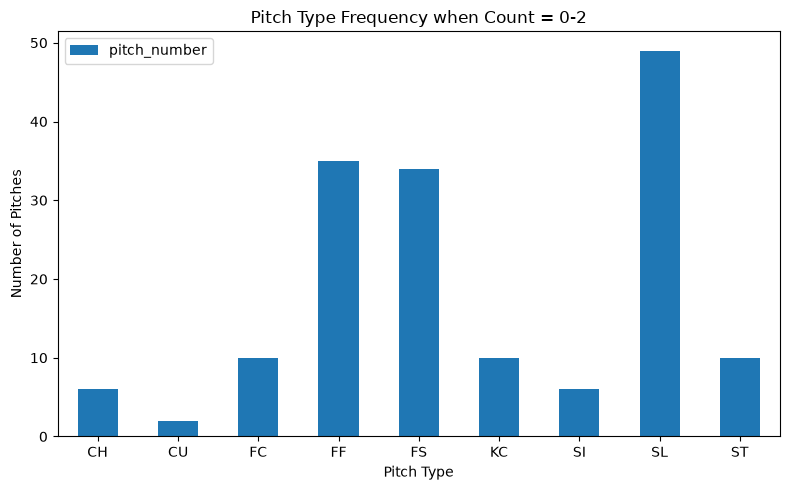

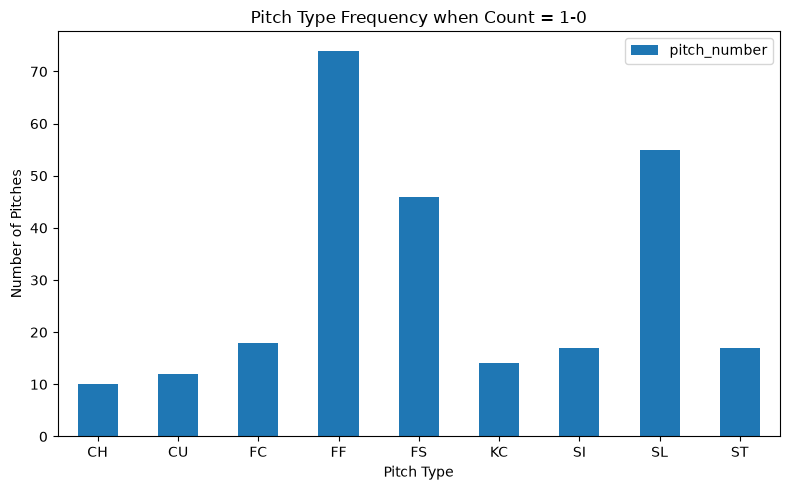

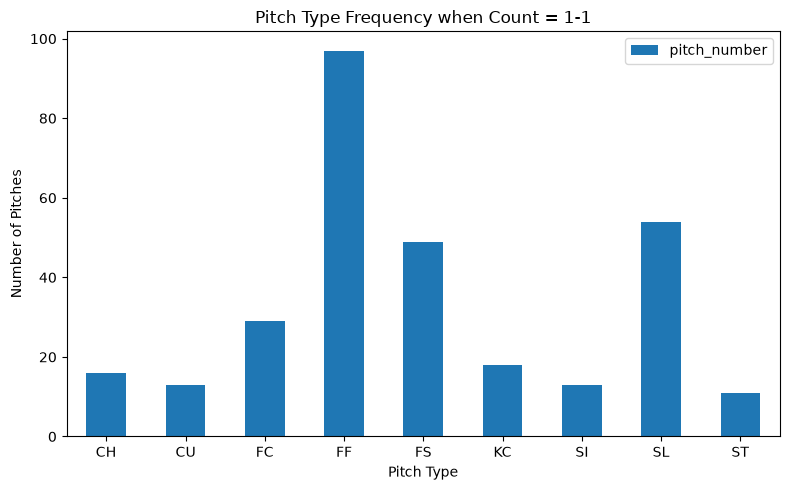

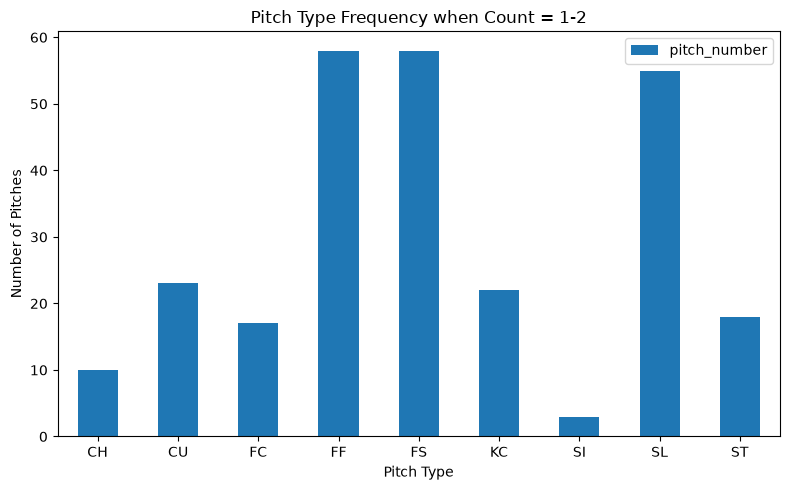

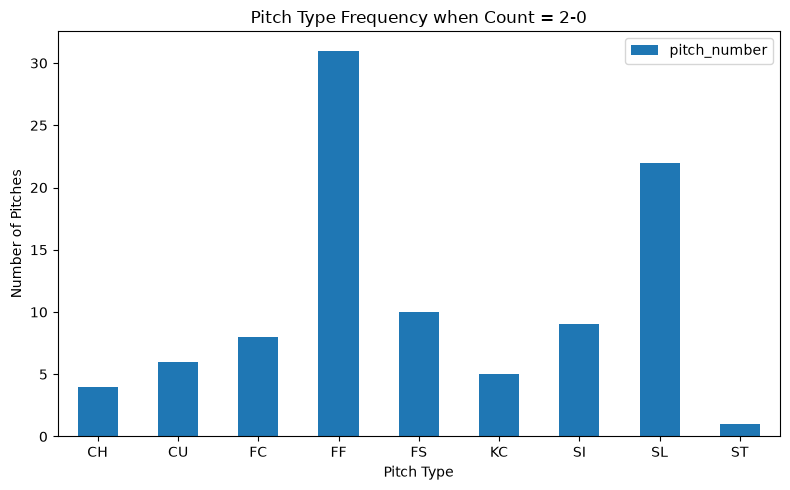

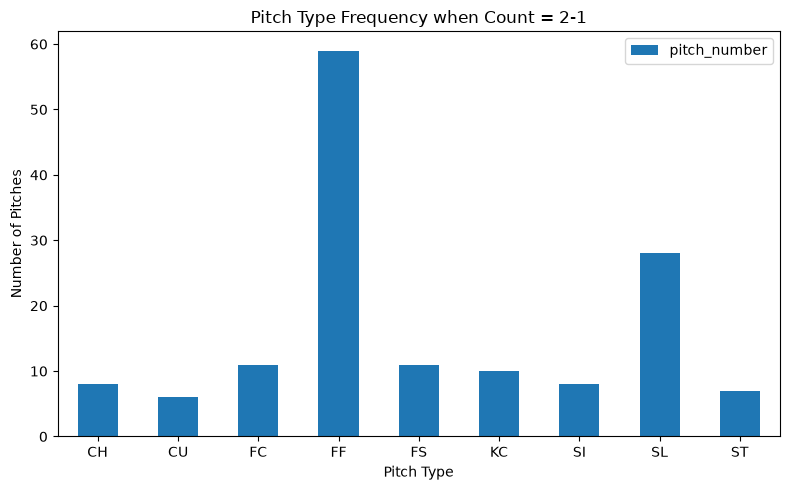

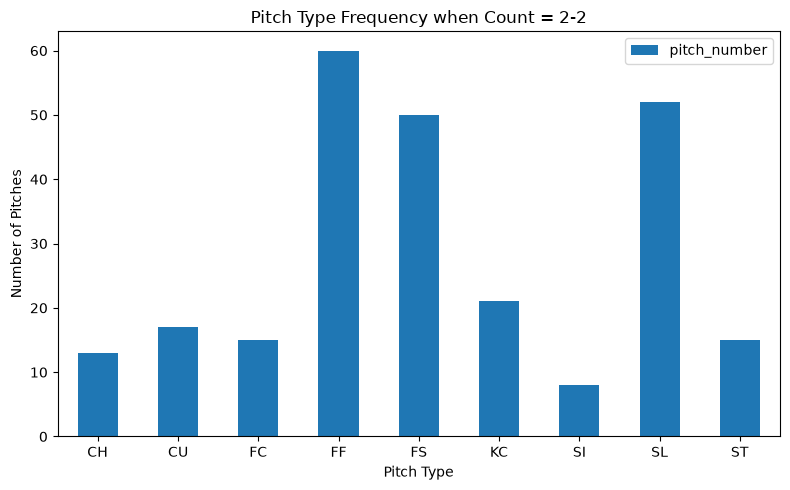

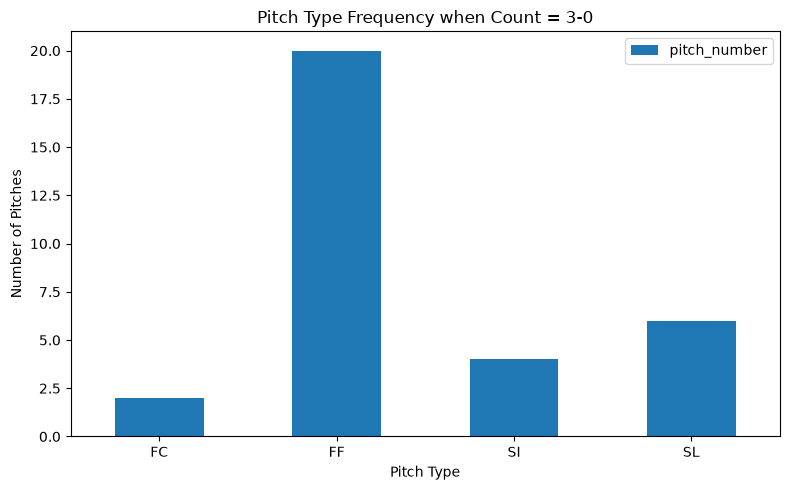

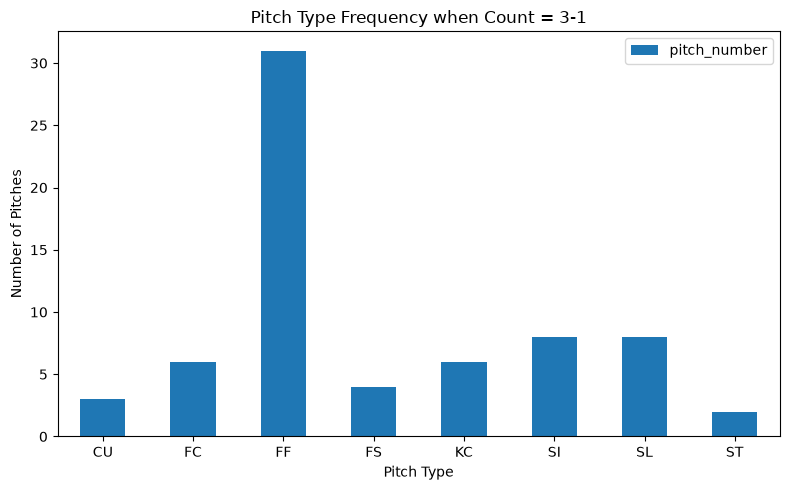

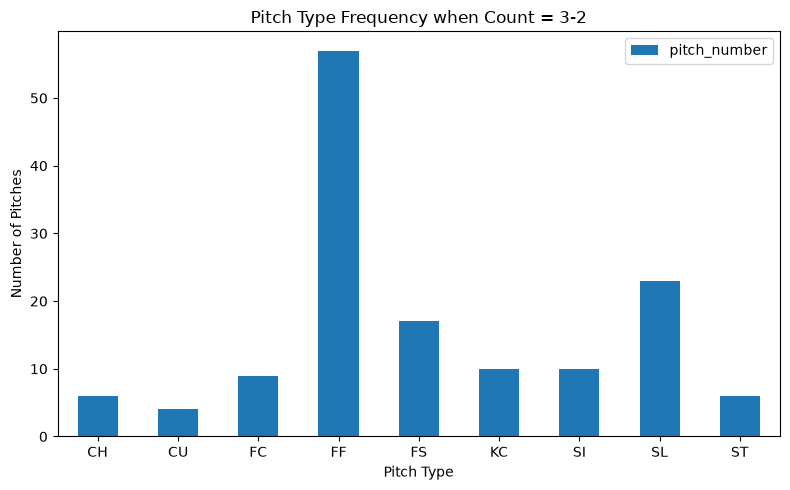

Count 0-0: Most frequent pitch = FF, Number = 307
Count 0-1: Most frequent pitch = FF, Number = 108
Count 0-2: Most frequent pitch = SL, Number = 49
Count 1-0: Most frequent pitch = FF, Number = 74
Count 1-1: Most frequent pitch = FF, Number = 97
Count 1-2: Most frequent pitch = FF, Number = 58
Count 2-0: Most frequent pitch = FF, Number = 31
Count 2-1: Most frequent pitch = FF, Number = 59
Count 2-2: Most frequent pitch = FF, Number = 60
Count 3-0: Most frequent pitch = FF, Number = 20
Count 3-1: Most frequent pitch = FF, Number = 31
Count 3-2: Most frequent pitch = FF, Number = 57


In [2]:
#sub2: How predictable is Blue Jays pitch selection at different counts?
display(HTML("<h1>Subquestion2: How predictable is Blue Jays pitch selection at different counts?</h1>"))
print("\n\n")
#create a new column to show different count
toronto["count"] = toronto["balls"].astype(str) + "-" + toronto["strikes"].astype(str)
toronto_count = toronto["count"]
toronto_pitch = toronto["pitch_type"]
#concat the pitch type and the count 
counts_different_table = pd.concat( [toronto_count, toronto_pitch], axis=1 )

# Reset index, drop the old index column (do not keep old index as new column)
counts_different_table = counts_different_table.reset_index(drop=True)

#display the new table which only include count and pitch type
display(HTML("<h4> Extracting important data: count and pitch_type</h4>"))
display(counts_different_table)


pitch_number_table = toronto.groupby(["count", "pitch_type"]).size().reset_index(name="pitch_number")
display(HTML("<h4> Classify pitch types into count groups</h4>"))
display(pitch_number_table)

#creat a bar chart to visualize
# Create pivot table from your pitch_count_summary
pivot_table = pitch_number_table.pivot(index="count", columns="pitch_type", values="pitch_number").fillna(0)

# Plot stacked bar
display(HTML("<h4>Transfer the table into a pivot bar chart</h4>"))
pivot_table.plot(kind="bar", stacked=True, figsize=(14,6))
plt.title("Pitch Type Distribution for Different Ball-Strike Counts")
plt.xlabel("Ball-Strike Count")
plt.ylabel("Total Number of Pitches")
plt.legend(title="Pitch Type", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


# loop to create separate bar chart for every count
display(HTML("<h4>Separate it into 12 different charts is terms of different counts</h4>"))
display(HTML("<p>This bar chart shows how many times each pitch type was thrown under this specific ball-strike count. It helps us see which pitch is most predictable in this game state.</p>"))
all_counts = pitch_number_table["count"].unique()

for one_count in all_counts:
    subset = pitch_number_table[pitch_number_table["count"] == one_count]
    subset.plot(kind="bar", x="pitch_type", y="pitch_number", figsize=(8,5))
    plt.title(f"Pitch Type Frequency when Count = {one_count}")
    plt.xlabel("Pitch Type")
    plt.ylabel("Number of Pitches")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()


#Get the result from bar chart.
display(HTML("<h4> Get the result from 12 charts</h4>"))

# Get unique count values, avoid repeating same count many times
all_counts = pitch_number_table["count"].unique()

for one_count in all_counts:
    # filter data for this single count
    subset = pitch_number_table[pitch_number_table["count"] == one_count]
    # find the row with maximum pitch_number
    max_row = subset.loc[subset["pitch_number"].idxmax()]
    
    best_pitch = max_row["pitch_type"]
    best_num = max_row["pitch_number"]
    
    print(f"Count {one_count}: Most frequent pitch = {best_pitch}, Number = {best_num}")

    

